# Análise Univariada de Vinhos

## Objetivo da Análise

Esta análise tem como objetivo explorar individualmente cada variável do dataset de vinhos, compreendendo suas distribuições, características estatísticas e padrões. A análise univariada é fundamental para:

- **Identificar outliers e valores atípicos** em cada variável
- **Compreender a distribuição** de cada característica dos vinhos
- **Detectar problemas de qualidade dos dados** (valores nulos, inconsistências)
- **Estabelecer baseline** para análises posteriores mais complexas
- **Definir estratégias de pré-processamento** baseadas no comportamento individual das variáveis

## Estrutura da Análise

### 1. Carregamento e Preparação dos Dados
- Importação das bibliotecas necessárias
- Carregamento do dataset
- Visão geral da estrutura dos dados

### 2. Análise Descritiva Geral
- Informações básicas do dataset (dimensões, tipos de dados)
- Estatísticas descritivas resumidas
- Verificação de valores nulos e duplicados

### 3. Análise Individual das Variáveis Numéricas
Para cada variável numérica, serão analisados:
- **Medidas de tendência central** (média, mediana, moda)
- **Medidas de dispersão** (desvio padrão, quartis, amplitude)
- **Distribuição** através de histogramas e box plots
- **Identificação de outliers**
- **Análise de assimetria e curtose**

### 4. Análise das Variáveis Categóricas
- **Frequência absoluta e relativa** de cada categoria
- **Gráficos de barras** para visualização
- **Identificação de categorias raras ou dominantes**

### 5. Visualizações Consolidadas
- Dashboard com principais métricas
- Comparação visual entre variáveis similares
- Identificação de padrões gerais

### 6. Insights e Conclusões
- Resumo dos principais achados
- Identificação de variáveis que necessitam tratamento
- Recomendações para próximas etapas de análise

---"

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Configurar estilo dos gráficos
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 10

In [4]:
# Importar carregador de dados personalizado
import sys
sys.path.append('../src')
from utils.carregador_dados import carregar_todos_dados

# Carregar todos os datasets corretos
dados = carregar_todos_dados('../data/')

# Datasets principais para análise
df_exp_espumantes = dados['exportacao_espumantes']
df_exp_vinho_mesa = dados['exportacao_vinho_mesa'] 
df_imp_espumantes = dados['importacao_espumantes']
df_imp_vinho_mesa = dados['importacao_vinho_mesa']

print("📊 Datasets carregados com sucesso!")
print(f"Exportação Espumantes: {df_exp_espumantes.shape}")
print(f"Exportação Vinho Mesa: {df_exp_vinho_mesa.shape}")
print(f"Importação Espumantes: {df_imp_espumantes.shape}")
print(f"Importação Vinho Mesa: {df_imp_vinho_mesa.shape}")

# Exibir preview dos dados
print("\n🔍 PREVIEW DOS DATASETS:")
print("\n1. Exportação de Espumantes:")
display(df_exp_espumantes.head())

print("\n2. Exportação de Vinho de Mesa:")
display(df_exp_vinho_mesa.head())

print("\n3. Importação de Espumantes:")
display(df_imp_espumantes.head())

print("\n4. Importação de Vinho de Mesa:")
display(df_imp_vinho_mesa.head())

✅ exportacao_espumantes: 107 linhas, 112 colunas
✅ exportacao_vinho_mesa: 141 linhas, 112 colunas
✅ producao: 51 linhas, 58 colunas
✅ importacao_espumantes: 46 linhas, 112 colunas
✅ importacao_vinho_mesa: 69 linhas, 112 colunas
Erro ao carregar dados de comércio: Error tokenizing data. C error: Expected 1 fields in line 29, saw 2

✅ comercio: 0 linhas, 0 colunas
Valores nulos por coluna:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64
✅ wine_quality: 1143 linhas, 13 colunas
📊 Datasets carregados com sucesso!
Exportação Espumantes: (107, 112)
Exportação Vinho Mesa: (141, 112)
Importação Espumantes: (46, 112)
Importação Vinho Mesa: (69, 112)

🔍 PREVIEW DOS DATASETS:

1. Exportação de Espuma

,Id,País,1970,1970.1,1971,1971.1,1972,1972.1,1973,1973.1,...,2020,2020.1,2021,2021.1,2022,2022.1,2023,2023.1,2024,2024.1
0,1,África do Sul,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,2,44,78,1353
1,2,Alemanha,0,0,0,0,0,0,0,0,...,2388,14767,142,265,1164,6560,162,1542,22542,77981
2,3,Angola,0,0,0,0,0,0,0,0,...,24,38,0,0,26383,141588,56242,315073,0,0
3,4,Antigua e Barbuda,0,0,0,0,0,0,0,0,...,32,328,10,82,65,146,24,100,23,100
4,5,Antilhas Holandesas,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



2. Exportação de Vinho de Mesa:


,Id,País,1970,1970.1,1971,1971.1,1972,1972.1,1973,1973.1,...,2020,2020.1,2021,2021.1,2022,2022.1,2023,2023.1,2024,2024.1
0,1,Afeganistão,0,0,0,0,0,0,0,0,...,0,0,11,46,0,0,0,0,0,0
1,2,África do Sul,0,0,0,0,0,0,0,0,...,4,21,0,0,0,0,117,698,103,1783
2,3,Alemanha,0,0,0,0,4168,2630,12000,8250,...,6261,32605,2698,6741,7630,45367,4806,31853,6666,48095
3,4,Angola,0,0,0,0,0,0,0,0,...,0,0,0,0,4068,4761,0,0,0,0
4,5,Anguilla,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



3. Importação de Espumantes:


,Id,País,1970,1970.1,1971,1971.1,1972,1972.1,1973,1973.1,...,2020,2020.1,2021,2021.1,2022,2022.1,2023,2023.1,2024,2024.1
0,1,Africa do Sul,0,0,0,0,0,0,0,0,...,3574,14542,6980,36677,9882,64582,7650,69382,2018,19706
1,2,Alemanha,0,0,25,36,2864,2479,2900,3130,...,21174,65359,19977,46237,12447,26877,322,5111,15168,46600
2,3,Argentina,4980,3836,8811,7543,35301,26909,39208,20230,...,469547,1304986,723847,2211657,1333420,4123623,839006,2765843,1171895,3786391
3,4,Austrália,0,0,0,0,0,0,0,0,...,7426,15190,8062,26208,0,0,3150,10474,15891,26618
4,5,Áustria,0,0,0,0,0,0,0,0,...,909,9399,90,1434,0,0,882,8833,0,0



4. Importação de Vinho de Mesa:


,Id,País,1970,1970.1,1971,1971.1,1972,1972.1,1973,1973.1,...,2020,2020.1,2021,2021.1,2022,2022.1,2023,2023.1,2024,2024.1
0,1,Africa do Sul,0,0,0,0,0,0,0,0,...,627150,1701072,859169,2508140,738116,2266827,522733,1732850,658238,2133775
1,2,Alemanha,52297,30498,34606,26027,134438,92103,111523,98638,...,136992,504168,106541,546967,92600,438595,102456,557947,121002,805466
2,3,Argélia,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,Arábia Saudita,0,0,0,0,0,0,0,0,...,0,0,2510,8761,0,0,8,161,0,0
4,5,Argentina,19525,12260,24942,15022,104906,58137,116887,76121,...,22610267,66322932,26869241,79527959,27980574,87519642,25276991,83918138,26272478,93869579


In [5]:
# 1. ANÁLISE DESCRITIVA GERAL DOS DATASETS

def analisar_dataset_geral(df, nome_dataset):
    """
    Realiza análise descritiva geral de um dataset
    """
    print(f"\n{'='*60}")
    print(f"📋 ANÁLISE GERAL: {nome_dataset.upper()}")
    print(f"{'='*60}")
    
    print(f"Número de observações: {df.shape[0]:,}")
    print(f"Número de variáveis: {df.shape[1]}")
    print(f"Memória utilizada: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
    
    print(f"\n📊 TIPOS DE DADOS:")
    print(df.dtypes)
    
    print(f"\n🔍 VALORES NULOS:")
    nulos = df.isnull().sum()
    nulos_encontrados = nulos[nulos > 0]
    if len(nulos_encontrados) > 0:
        print(nulos_encontrados)
    else:
        print("Não há valores nulos no dataset")
    
    print(f"\n🔄 DUPLICATAS:")
    duplicatas = df.duplicated().sum()
    print(f"Número de linhas duplicadas: {duplicatas}")
    
    # Remover duplicatas se existirem
    if duplicatas > 0:
        print("Removendo duplicatas...")
        df_limpo = df.drop_duplicates()
        print(f"Novo tamanho do dataset: {df_limpo.shape}")
        return df_limpo
    
    return df

# Analisar cada dataset
datasets = {
    'Exportação de Espumantes': df_exp_espumantes,
    'Exportação de Vinho de Mesa': df_exp_vinho_mesa,
    'Importação de Espumantes': df_imp_espumantes,
    'Importação de Vinho de Mesa': df_imp_vinho_mesa
}

datasets_limpos = {}
for nome, df in datasets.items():
    datasets_limpos[nome] = analisar_dataset_geral(df, nome)


📋 ANÁLISE GERAL: EXPORTAÇÃO DE ESPUMANTES
Número de observações: 107
Número de variáveis: 112
Memória utilizada: 0.10 MB

📊 TIPOS DE DADOS:
Id         int64
País      object
1970       int64
1970.1     int64
1971       int64
           ...  
2022.1     int64
2023       int64
2023.1     int64
2024       int64
2024.1     int64
Length: 112, dtype: object

🔍 VALORES NULOS:
Não há valores nulos no dataset

🔄 DUPLICATAS:
Número de linhas duplicadas: 0

📋 ANÁLISE GERAL: EXPORTAÇÃO DE VINHO DE MESA
Número de observações: 141
Número de variáveis: 112
Memória utilizada: 0.13 MB

📊 TIPOS DE DADOS:
Id         int64
País      object
1970       int64
1970.1     int64
1971       int64
           ...  
2022.1     int64
2023       int64
2023.1     int64
2024       int64
2024.1     int64
Length: 112, dtype: object

🔍 VALORES NULOS:
Não há valores nulos no dataset

🔄 DUPLICATAS:
Número de linhas duplicadas: 0

📋 ANÁLISE GERAL: IMPORTAÇÃO DE ESPUMANTES
Número de observações: 46
Número de variáveis: 112
M

In [6]:
# 2. ESTATÍSTICAS DESCRITIVAS POR DATASET

def obter_estatisticas_dataset(df, nome_dataset):
    """
    Obtém estatísticas descritivas de um dataset
    """
    print(f"\n{'='*60}")
    print(f"📈 ESTATÍSTICAS DESCRITIVAS - {nome_dataset.upper()}")
    print(f"{'='*60}")
    
    # Separar variáveis numéricas e categóricas
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
    
    print(f"Variáveis numéricas ({len(numeric_cols)}): {numeric_cols}")
    print(f"Variáveis categóricas ({len(categorical_cols)}): {categorical_cols}")
    
    if len(numeric_cols) > 0:
        print(f"\n📊 ESTATÍSTICAS RESUMIDAS - VARIÁVEIS NUMÉRICAS:")
        stats = df[numeric_cols].describe().round(2)
        display(stats)
        return numeric_cols, categorical_cols, stats
    else:
        print("Não há variáveis numéricas para análise estatística")
        return [], categorical_cols, None

# Analisar estatísticas de cada dataset
estatisticas_datasets = {}
for nome, df in datasets_limpos.items():
    num_cols, cat_cols, stats = obter_estatisticas_dataset(df, nome)
    estatisticas_datasets[nome] = {
        'numeric_cols': num_cols,
        'categorical_cols': cat_cols,
        'stats': stats,
        'dataframe': df
    }


📈 ESTATÍSTICAS DESCRITIVAS - EXPORTAÇÃO DE ESPUMANTES
Variáveis numéricas (111): ['Id', '1970', '1970.1', '1971', '1971.1', '1972', '1972.1', '1973', '1973.1', '1974', '1974.1', '1975', '1975.1', '1976', '1976.1', '1977', '1977.1', '1978', '1978.1', '1979', '1979.1', '1980', '1980.1', '1981', '1981.1', '1982', '1982.1', '1983', '1983.1', '1984', '1984.1', '1985', '1985.1', '1986', '1986.1', '1987', '1987.1', '1988', '1988.1', '1989', '1989.1', '1990', '1990.1', '1991', '1991.1', '1992', '1992.1', '1993', '1993.1', '1994', '1994.1', '1995', '1995.1', '1996', '1996.1', '1997', '1997.1', '1998', '1998.1', '1999', '1999.1', '2000', '2000.1', '2001', '2001.1', '2002', '2002.1', '2003', '2003.1', '2004', '2004.1', '2005', '2005.1', '2006', '2006.1', '2007', '2007.1', '2008', '2008.1', '2009', '2009.1', '2010', '2010.1', '2011', '2011.1', '2012', '2012.1', '2013', '2013.1', '2014', '2014.1', '2015', '2015.1', '2016', '2016.1', '2017', '2017.1', '2018', '2018.1', '2019', '2019.1', '2020', '20

,Id,1970,1970.1,1971,1971.1,1972,1972.1,1973,1973.1,1974,...,2020,2020.1,2021,2021.1,2022,2022.1,2023,2023.1,2024,2024.1
count,107.00,107.00,107.00,107.00,107.00,107.00,107.00,107.0,107.00,107.00,...,107.00,107.00,107.00,107.00,107.00,107.00,107.00,107.00,107.00,107.00
mean,54.00,52.18,31.63,4.77,2.75,32.40,14.78,710.5,469.68,77.06,...,7206.22,20075.90,8740.59,24260.47,8690.33,26783.03,4696.31,17988.08,4291.36,17361.79
std,31.03,497.35,310.32,37.07,21.69,222.21,91.67,7312.0,4829.11,764.14,...,61337.31,159453.45,77494.34,205533.97,70869.22,190903.03,25931.17,79194.04,15874.95,57003.09
min,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,27.50,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,54.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,80.50,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,...,423.50,1415.50,175.50,661.00,618.00,3402.50,756.50,3947.50,720.00,3021.50
max,107.00,5132.00,3208.00,350.00,208.00,1951.00,697.00,75639.0,49955.00,7900.00,...,634243.00,1647310.00,801082.00,2123710.00,732209.00,1964451.00,255198.00,729055.00,110205.00,394394.00



📈 ESTATÍSTICAS DESCRITIVAS - EXPORTAÇÃO DE VINHO DE MESA
Variáveis numéricas (111): ['Id', '1970', '1970.1', '1971', '1971.1', '1972', '1972.1', '1973', '1973.1', '1974', '1974.1', '1975', '1975.1', '1976', '1976.1', '1977', '1977.1', '1978', '1978.1', '1979', '1979.1', '1980', '1980.1', '1981', '1981.1', '1982', '1982.1', '1983', '1983.1', '1984', '1984.1', '1985', '1985.1', '1986', '1986.1', '1987', '1987.1', '1988', '1988.1', '1989', '1989.1', '1990', '1990.1', '1991', '1991.1', '1992', '1992.1', '1993', '1993.1', '1994', '1994.1', '1995', '1995.1', '1996', '1996.1', '1997', '1997.1', '1998', '1998.1', '1999', '1999.1', '2000', '2000.1', '2001', '2001.1', '2002', '2002.1', '2003', '2003.1', '2004', '2004.1', '2005', '2005.1', '2006', '2006.1', '2007', '2007.1', '2008', '2008.1', '2009', '2009.1', '2010', '2010.1', '2011', '2011.1', '2012', '2012.1', '2013', '2013.1', '2014', '2014.1', '2015', '2015.1', '2016', '2016.1', '2017', '2017.1', '2018', '2018.1', '2019', '2019.1', '2020', 

,Id,1970,1970.1,1971,1971.1,1972,1972.1,1973,1973.1,1974,...,2020,2020.1,2021,2021.1,2022,2022.1,2023,2023.1,2024,2024.1
count,141.00,141.00,141.00,141.00,141.00,141.00,141.00,141.00,141.00,141.00,...,141.00,141.00,141.00,141.00,141.00,141.00,141.00,141.00,141.00,141.00
mean,71.00,964.60,287.23,1995.07,591.95,2702.27,858.84,3342.34,1239.66,2531.81,...,31274.59,43108.43,57153.93,69871.93,49829.67,77626.11,39282.89,63284.23,37762.16,62065.78
std,40.85,7782.54,2137.88,20110.80,5449.71,24911.31,7281.88,28596.34,9910.43,21074.53,...,280507.87,332404.69,551691.70,609542.15,432659.57,611470.60,322724.68,471867.63,314917.23,438598.04
min,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,36.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,71.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,2.00,6.00,6.00,13.00,7.00,33.00,9.00,30.00,6.00,35.00
75%,106.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,990.00,3703.00,1172.00,6157.00,1485.00,5823.00,2265.00,7177.00,2273.00,8334.00
max,141.00,89846.00,23980.00,237805.00,64075.00,291625.00,84402.00,332433.00,115041.00,243294.00,...,3299013.00,3869243.00,6522527.00,7192362.00,5076670.00,7156293.00,3780378.00,5517263.00,3705268.00,5121857.00



📈 ESTATÍSTICAS DESCRITIVAS - IMPORTAÇÃO DE ESPUMANTES
Variáveis numéricas (111): ['Id', '1970', '1970.1', '1971', '1971.1', '1972', '1972.1', '1973', '1973.1', '1974', '1974.1', '1975', '1975.1', '1976', '1976.1', '1977', '1977.1', '1978', '1978.1', '1979', '1979.1', '1980', '1980.1', '1981', '1981.1', '1982', '1982.1', '1983', '1983.1', '1984', '1984.1', '1985', '1985.1', '1986', '1986.1', '1987', '1987.1', '1988', '1988.1', '1989', '1989.1', '1990', '1990.1', '1991', '1991.1', '1992', '1992.1', '1993', '1993.1', '1994', '1994.1', '1995', '1995.1', '1996', '1996.1', '1997', '1997.1', '1998', '1998.1', '1999', '1999.1', '2000', '2000.1', '2001', '2001.1', '2002', '2002.1', '2003', '2003.1', '2004', '2004.1', '2005', '2005.1', '2006', '2006.1', '2007', '2007.1', '2008', '2008.1', '2009', '2009.1', '2010', '2010.1', '2011', '2011.1', '2012', '2012.1', '2013', '2013.1', '2014', '2014.1', '2015', '2015.1', '2016', '2016.1', '2017', '2017.1', '2018', '2018.1', '2019', '2019.1', '2020', '20

,Id,1970,1970.1,1971,1971.1,1972,1972.1,1973,1973.1,1974,...,2020,2020.1,2021,2021.1,2022,2022.1,2023,2023.1,2024,2024.1
count,46.00,46.00,46.00,46.00,46.00,46.00,46.00,46.00,46.00,46.00,...,46.00,46.00,46.00,46.00,46.00,46.00,46.00,46.00,46.00,46.00
mean,23.50,832.89,1354.37,1086.17,1994.26,2611.39,3675.07,3653.04,6383.46,3751.04,...,107556.98,415150.43,115505.63,539471.74,141072.93,604122.24,159718.70,844059.50,155421.80,918893.65
std,13.42,3349.12,6847.02,4236.29,10743.54,8396.37,15134.88,11479.48,28172.16,14120.53,...,344959.08,1488995.13,380579.68,2072637.02,446455.53,2201021.49,569316.86,3313567.24,488308.94,3774839.69
min,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,12.25,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,23.50,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,6.50
75%,34.75,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,3286.00,17286.75,523.50,2879.75,1299.00,3563.25,847.25,9913.00,1887.00,17692.25
max,46.00,18458.00,45798.00,26523.00,72645.00,35899.00,97186.00,49453.00,186096.00,83575.00,...,1524542.00,8814571.00,2016806.00,12590570.00,2236061.00,13164535.00,3438264.00,20166147.00,2566076.00,24231961.00



📈 ESTATÍSTICAS DESCRITIVAS - IMPORTAÇÃO DE VINHO DE MESA
Variáveis numéricas (111): ['Id', '1970', '1970.1', '1971', '1971.1', '1972', '1972.1', '1973', '1973.1', '1974', '1974.1', '1975', '1975.1', '1976', '1976.1', '1977', '1977.1', '1978', '1978.1', '1979', '1979.1', '1980', '1980.1', '1981', '1981.1', '1982', '1982.1', '1983', '1983.1', '1984', '1984.1', '1985', '1985.1', '1986', '1986.1', '1987', '1987.1', '1988', '1988.1', '1989', '1989.1', '1990', '1990.1', '1991', '1991.1', '1992', '1992.1', '1993', '1993.1', '1994', '1994.1', '1995', '1995.1', '1996', '1996.1', '1997', '1997.1', '1998', '1998.1', '1999', '1999.1', '2000', '2000.1', '2001', '2001.1', '2002', '2002.1', '2003', '2003.1', '2004', '2004.1', '2005', '2005.1', '2006', '2006.1', '2007', '2007.1', '2008', '2008.1', '2009', '2009.1', '2010', '2010.1', '2011', '2011.1', '2012', '2012.1', '2013', '2013.1', '2014', '2014.1', '2015', '2015.1', '2016', '2016.1', '2017', '2017.1', '2018', '2018.1', '2019', '2019.1', '2020', 

,Id,1970,1970.1,1971,1971.1,1972,1972.1,1973,1973.1,1974,...,2020,2020.1,2021,2021.1,2022,2022.1,2023,2023.1,2024,2024.1
count,69.00,69.00,69.00,69.00,69.00,69.00,69.00,69.00,69.00,69.00,...,69.00,6.900000e+01,69.00,6.900000e+01,69.00,6.900000e+01,69.00,6.900000e+01,69.00,6.900000e+01
mean,35.00,20935.91,12809.94,21016.74,13577.59,40029.74,27384.74,59431.52,48888.62,61526.49,...,2132393.29,5.836133e+06,2241892.04,6.546827e+06,2139139.93,6.260567e+06,1995838.71,6.207140e+06,2219162.75,6.972217e+06
std,20.06,101206.60,66188.25,110311.36,75642.57,203559.24,149828.27,343035.36,275076.69,284494.30,...,9578459.68,2.419161e+07,9511474.25,2.591962e+07,9365458.50,2.581834e+07,8607244.61,2.459864e+07,9870920.18,2.841806e+07
min,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000000e+00,0.00,0.000000e+00,0.00,0.000000e+00,0.00,0.000000e+00,0.00,0.000000e+00
25%,18.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000000e+00,0.00,0.000000e+00,0.00,0.000000e+00,0.00,0.000000e+00,0.00,0.000000e+00
50%,35.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000000e+00,7.00,1.410000e+02,0.00,0.000000e+00,14.00,1.062000e+03,0.00,0.000000e+00
75%,52.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,15372.00,5.234800e+04,24194.00,9.956200e+04,29929.00,8.408400e+04,28806.00,1.242830e+05,25718.00,1.049650e+05
max,69.00,785609.00,531480.00,897310.00,620790.00,1650727.00,1226232.00,2818320.00,2238637.00,2245288.00,...,72726186.00,1.765405e+08,69617587.00,1.825681e+08,68881232.00,1.843353e+08,62358765.00,1.701462e+08,73111416.00,1.998748e+08


In [7]:
# 3. ANÁLISE INDIVIDUAL DAS VARIÁVEIS NUMÉRICAS (ANOS DE DADOS)

def analisar_variavel_numerica_temporal(df, coluna, nome_dataset):
    """
    Realiza análise completa de uma variável numérica temporal (anos)
    """
    dados = df[coluna]
    
    print(f"\n🔍 ANÁLISE TEMPORAL: {nome_dataset} - {coluna}")
    print("-" * 60)
    
    # Medidas de tendência central
    print(f"Média: {dados.mean():.2f}")
    print(f"Mediana: {dados.median():.2f}")
    print(f"Valor Máximo: {dados.max():.2f}")
    print(f"Valor Mínimo: {dados.min():.2f}")
    
    # Medidas de dispersão
    print(f"Desvio Padrão: {dados.std():.2f}")
    print(f"Coeficiente de Variação: {(dados.std()/dados.mean())*100:.2f}%")
    
    # Percentis importantes
    print(f"Q1 (25%): {dados.quantile(0.25):.2f}")
    print(f"Q3 (75%): {dados.quantile(0.75):.2f}")
    
    # Valores zero (países que não exportaram/importaram)
    zeros = (dados == 0).sum()
    print(f"Valores zero: {zeros} ({zeros/len(dados)*100:.1f}%)")
    
    # Outliers (método IQR)
    q1, q3 = dados.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = dados[(dados < lower_bound) | (dados > upper_bound)]
    print(f"Outliers detectados: {len(outliers)} ({len(outliers)/len(dados)*100:.1f}%)")
    
    return {
        'media': dados.mean(),
        'mediana': dados.median(),
        'desvio_padrao': dados.std(),
        'outliers': len(outliers),
        'zeros': zeros,
        'max': dados.max(),
        'min': dados.min()
    }

# Análise de todas as variáveis numéricas (anos) de cada dataset
resultados_analise_temporal = {}

for nome_dataset, info in estatisticas_datasets.items():
    df = info['dataframe']
    numeric_cols = info['numeric_cols']
    
    if len(numeric_cols) > 0:
        print(f"\n{'='*80}")
        print(f"🔍 ANÁLISE DETALHADA: {nome_dataset.upper()}")
        print(f"{'='*80}")
        
        resultados_dataset = {}
        for col in numeric_cols:
            if col.isdigit():  # Apenas colunas de anos
                resultados_dataset[col] = analisar_variavel_numerica_temporal(df, col, nome_dataset)
        
        resultados_analise_temporal[nome_dataset] = resultados_dataset


🔍 ANÁLISE DETALHADA: EXPORTAÇÃO DE ESPUMANTES

🔍 ANÁLISE TEMPORAL: Exportação de Espumantes - 1970
------------------------------------------------------------
Média: 52.18
Mediana: 0.00
Valor Máximo: 5132.00
Valor Mínimo: 0.00
Desvio Padrão: 497.35
Coeficiente de Variação: 953.18%
Q1 (25%): 0.00
Q3 (75%): 0.00
Valores zero: 104 (97.2%)
Outliers detectados: 3 (2.8%)

🔍 ANÁLISE TEMPORAL: Exportação de Espumantes - 1971
------------------------------------------------------------
Média: 4.77
Mediana: 0.00
Valor Máximo: 350.00
Valor Mínimo: 0.00
Desvio Padrão: 37.07
Coeficiente de Variação: 777.76%
Q1 (25%): 0.00
Q3 (75%): 0.00
Valores zero: 105 (98.1%)
Outliers detectados: 2 (1.9%)

🔍 ANÁLISE TEMPORAL: Exportação de Espumantes - 1972
------------------------------------------------------------
Média: 32.40
Mediana: 0.00
Valor Máximo: 1951.00
Valor Mínimo: 0.00
Desvio Padrão: 222.21
Coeficiente de Variação: 685.79%
Q1 (25%): 0.00
Q3 (75%): 0.00
Valores zero: 104 (97.2%)
Outliers detectad


🔍 VISUALIZAÇÕES TEMPORAIS: Exportação de Espumantes
------------------------------------------------------------


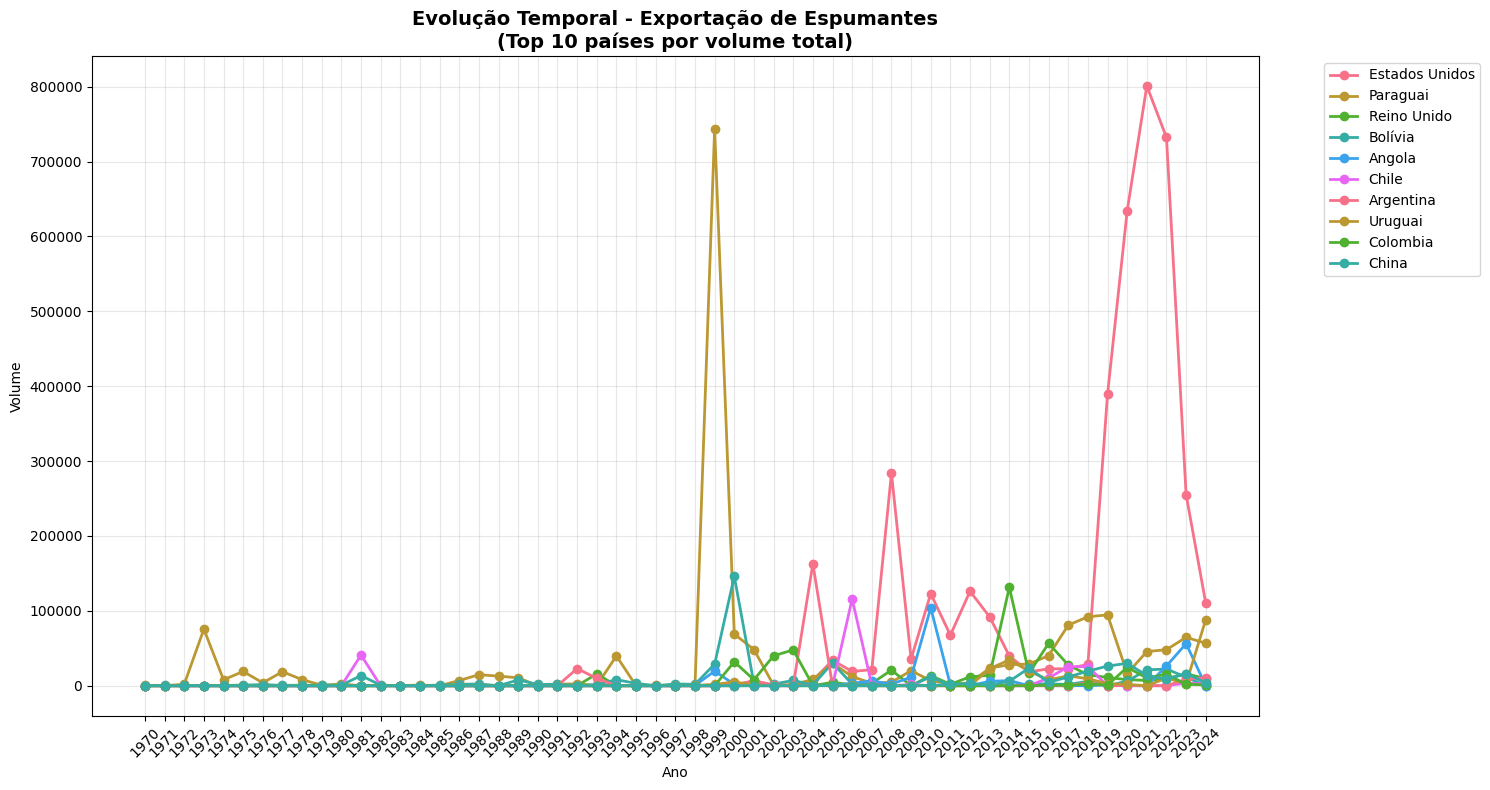

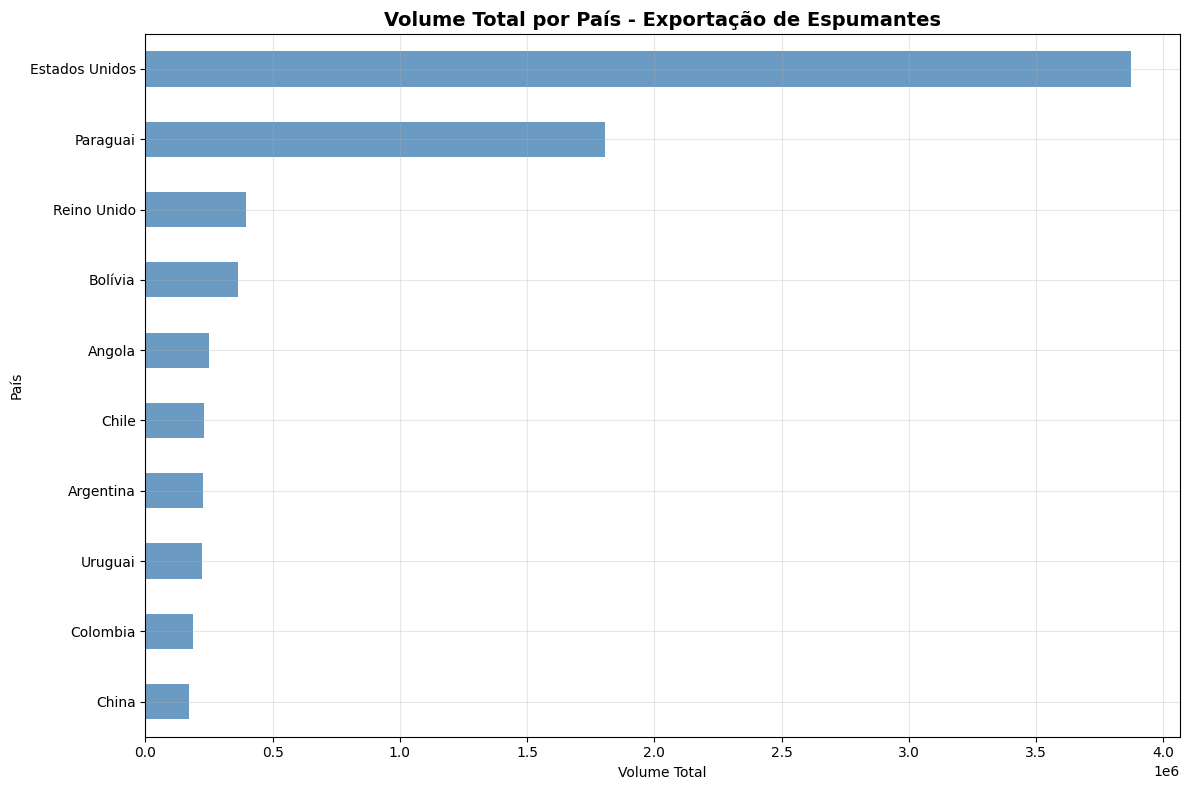


Top 5 países em Exportação de Espumantes:
          País   Total
Estados Unidos 3872386
      Paraguai 1806993
   Reino Unido  394897
       Bolívia  362546
        Angola  249550

🔍 VISUALIZAÇÕES TEMPORAIS: Exportação de Vinho de Mesa
------------------------------------------------------------


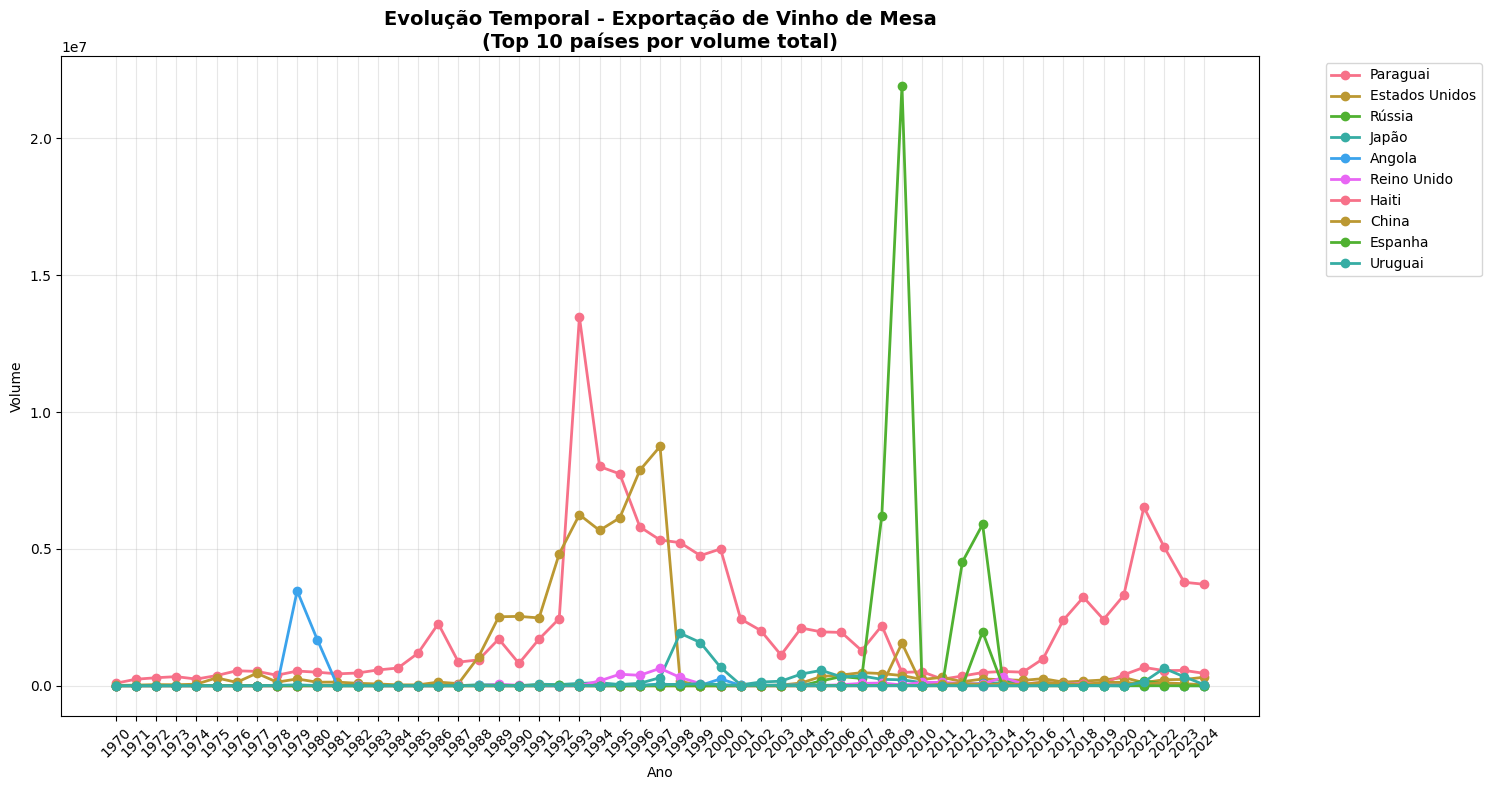

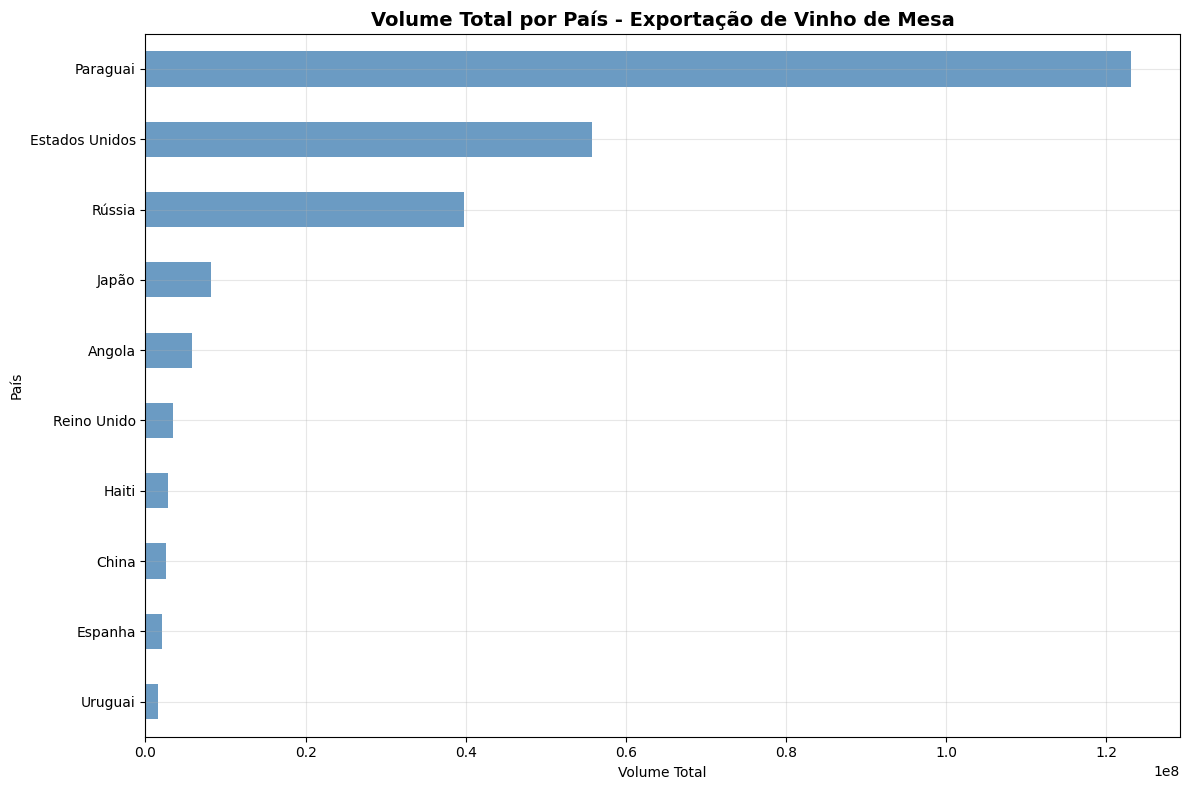


Top 5 países em Exportação de Vinho de Mesa:
          País     Total
      Paraguai 123029393
Estados Unidos  55799207
        Rússia  39808070
         Japão   8251198
        Angola   5819857

🔍 VISUALIZAÇÕES TEMPORAIS: Importação de Espumantes
------------------------------------------------------------


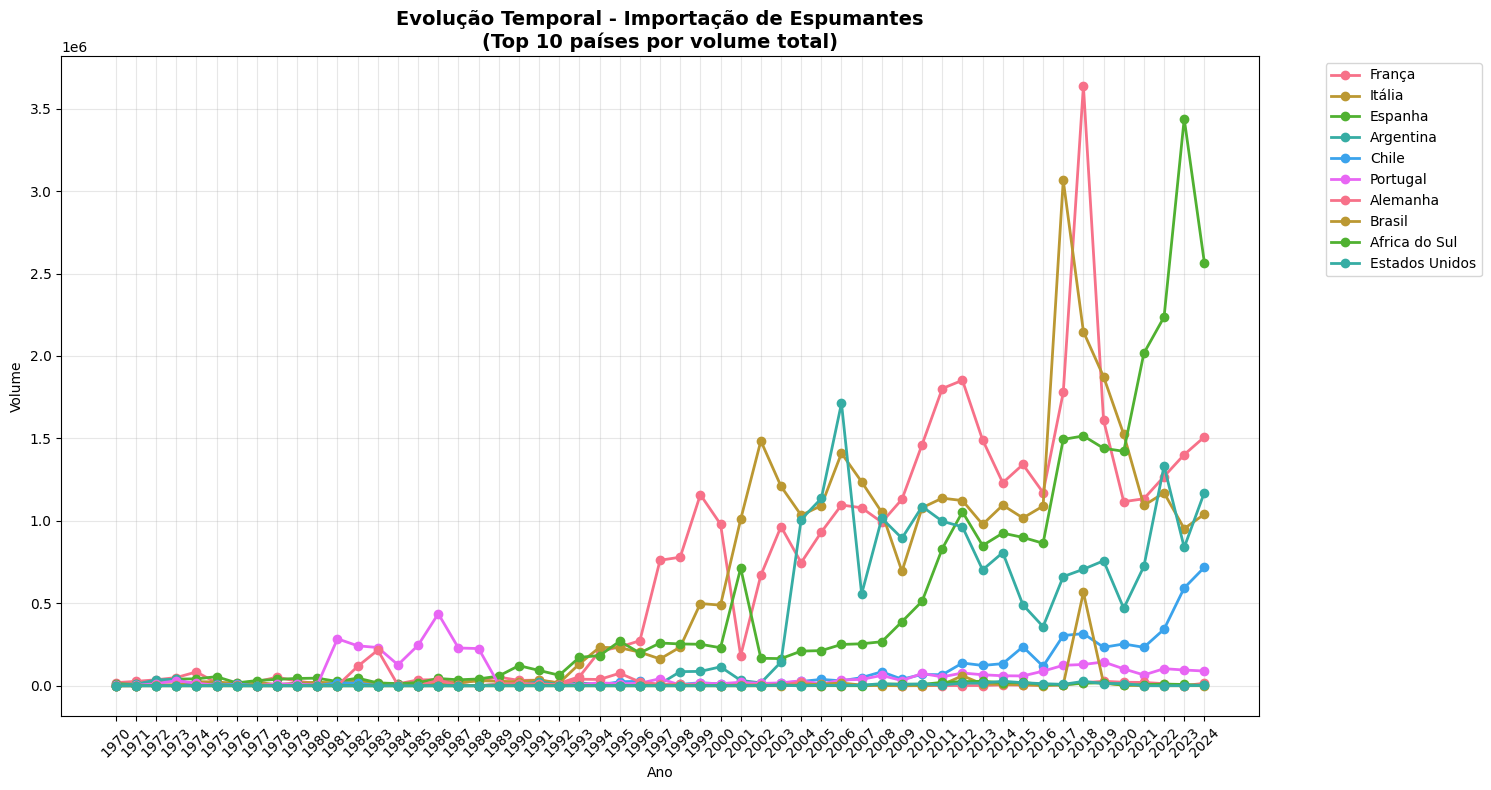

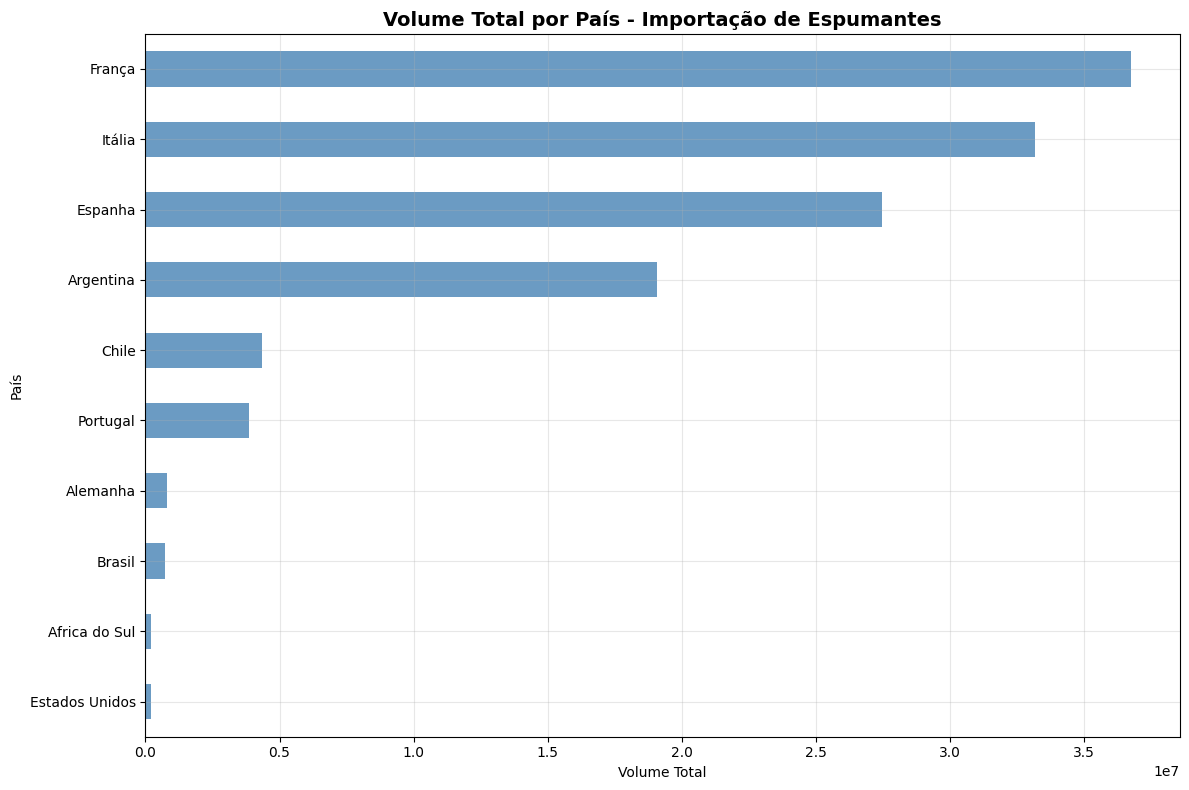


Top 5 países em Importação de Espumantes:
     País    Total
   França 36728095
   Itália 33174559
  Espanha 27453700
Argentina 19087527
    Chile  4352235

🔍 VISUALIZAÇÕES TEMPORAIS: Importação de Vinho de Mesa
------------------------------------------------------------


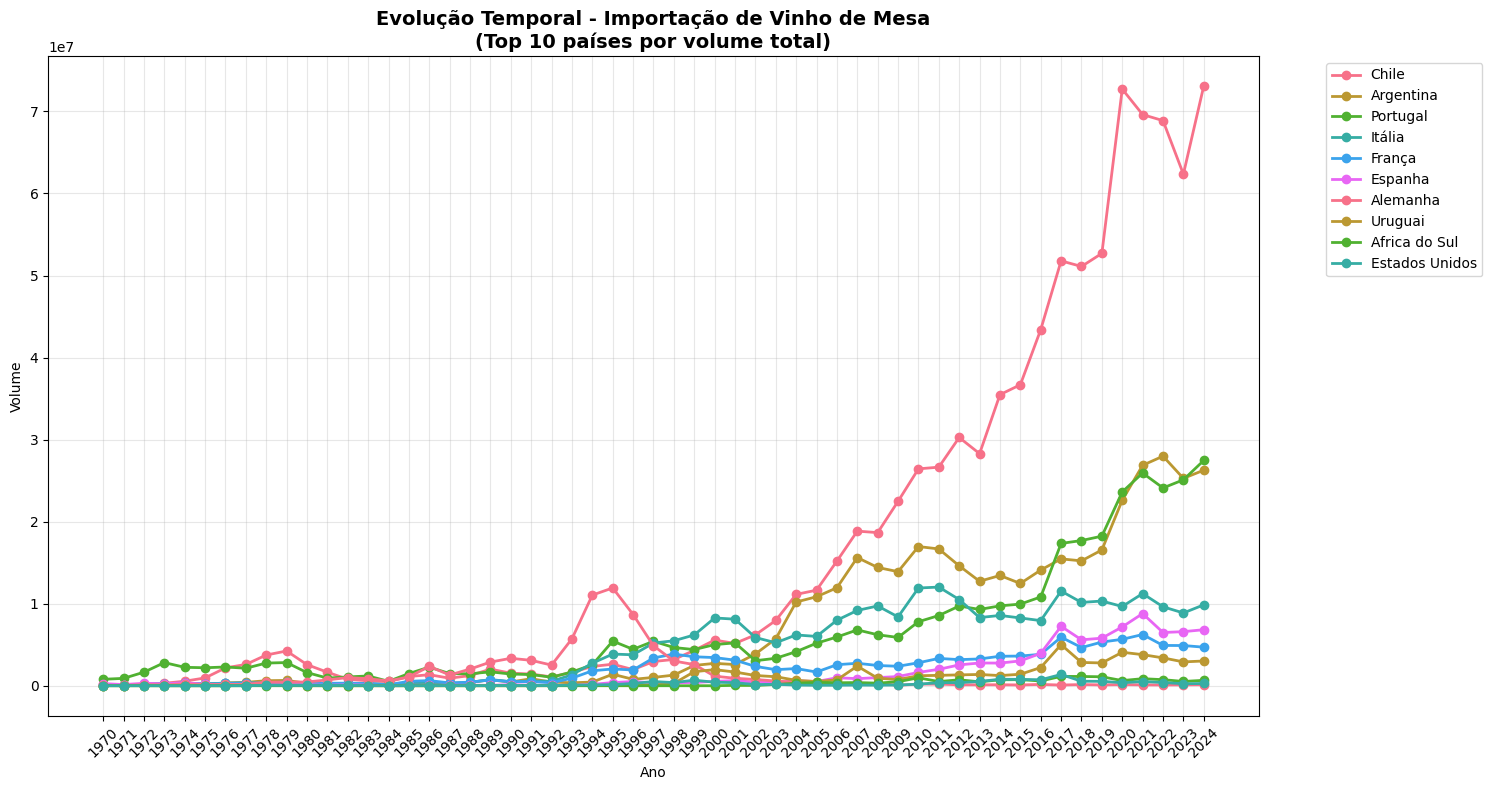

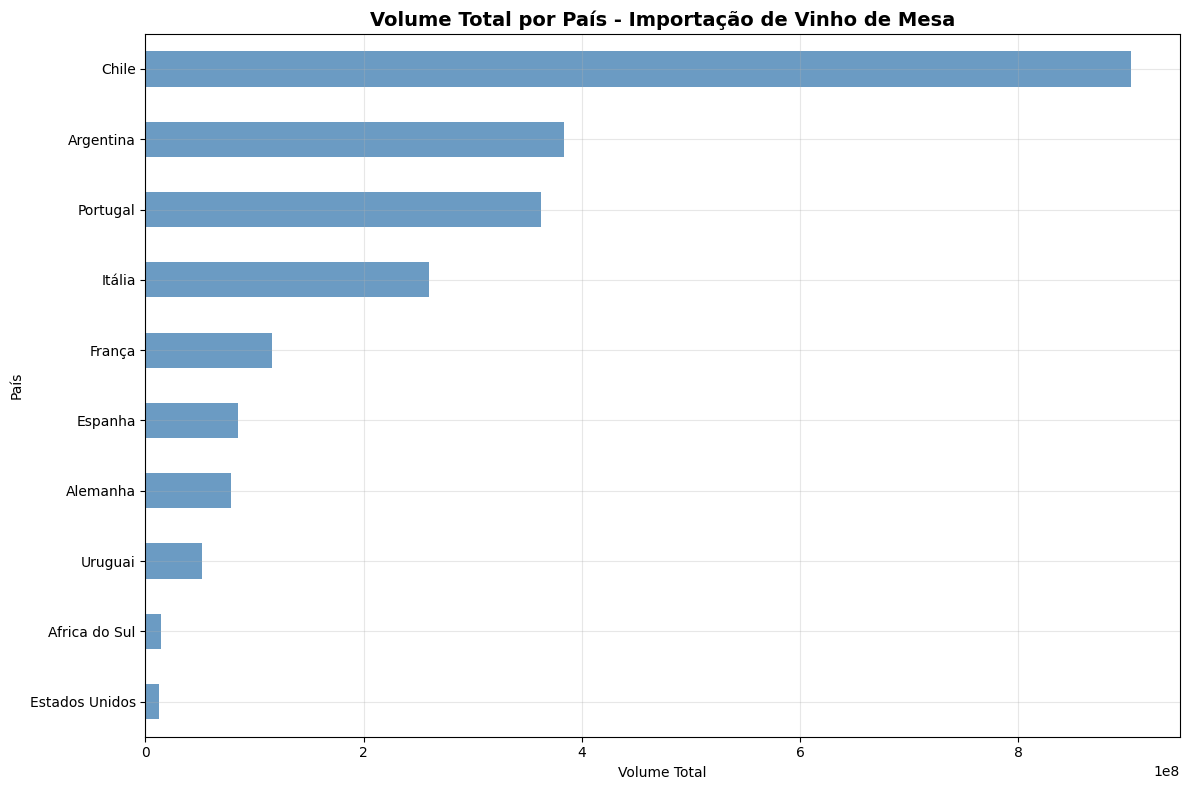


Top 5 países em Importação de Vinho de Mesa:
     País     Total
    Chile 903056644
Argentina 383532801
 Portugal 362901435
   Itália 259668757
   França 115947488


In [8]:
# 4. VISUALIZAÇÕES - EVOLUÇÃO TEMPORAL POR DATASET

def plotar_evolucao_temporal(df, nome_dataset, max_paises=10):
    """
    Plota a evolução temporal dos principais países
    """
    # Identificar colunas de anos
    anos_cols = [col for col in df.columns if col.isdigit()]
    anos_cols.sort()
    
    if len(anos_cols) == 0:
        print(f"Não há dados temporais para {nome_dataset}")
        return
    
    # Calcular total por país (soma de todos os anos)
    if 'País' in df.columns:
        df_totais = df.copy()
        df_totais['Total'] = df_totais[anos_cols].sum(axis=1)
        top_paises = df_totais.nlargest(max_paises, 'Total')
        
        # Plotar evolução dos top países
        plt.figure(figsize=(15, 8))
        
        for idx, row in top_paises.iterrows():
            pais = row['País']
            valores = [row[ano] for ano in anos_cols]
            plt.plot(anos_cols, valores, marker='o', linewidth=2, label=pais)
        
        plt.title(f'Evolução Temporal - {nome_dataset}\n(Top {max_paises} países por volume total)', 
                 fontsize=14, fontweight='bold')
        plt.xlabel('Ano')
        plt.ylabel('Volume')
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.grid(True, alpha=0.3)
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
        
        # Gráfico de barras dos totais
        plt.figure(figsize=(12, 8))
        totais_plot = top_paises.set_index('País')['Total'].sort_values(ascending=True)
        totais_plot.plot(kind='barh', color='steelblue', alpha=0.8)
        plt.title(f'Volume Total por País - {nome_dataset}', fontsize=14, fontweight='bold')
        plt.xlabel('Volume Total')
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
        
        return top_paises
    else:
        print(f"Coluna 'País' não encontrada em {nome_dataset}")

# Plotar evolução temporal para cada dataset
for nome_dataset, info in estatisticas_datasets.items():
    df = info['dataframe']
    print(f"\n🔍 VISUALIZAÇÕES TEMPORAIS: {nome_dataset}")
    print("-" * 60)
    
    top_paises = plotar_evolucao_temporal(df, nome_dataset)
    
    if top_paises is not None and len(top_paises) > 0:
        print(f"\nTop 5 países em {nome_dataset}:")
        print(top_paises[['País', 'Total']].head().to_string(index=False))


📊 ANÁLISE DE DISTRIBUIÇÕES: Exportação de Espumantes
------------------------------------------------------------
Estatísticas por Ano:


,total,media,mediana,desvio,max,paises_ativos,zeros
1970,5583.0,52.18,0.0,497.35,5132.0,3.0,104.0
1971,510.0,4.77,0.0,37.07,350.0,2.0,105.0
1972,3467.0,32.40,0.0,222.21,1951.0,3.0,104.0
1973,76023.0,710.50,0.0,7312.00,75639.0,3.0,104.0
1974,8245.0,77.06,0.0,764.14,7900.0,2.0,105.0
1975,20163.0,188.44,0.0,1843.85,19062.0,3.0,104.0
1976,8307.0,77.64,0.0,434.19,3847.0,5.0,102.0
1977,21516.0,201.08,0.0,1818.07,18759.0,4.0,103.0
1978,10930.0,102.15,0.0,793.81,8122.0,6.0,101.0
1979,4186.0,39.12,0.0,168.10,1040.0,6.0,101.0


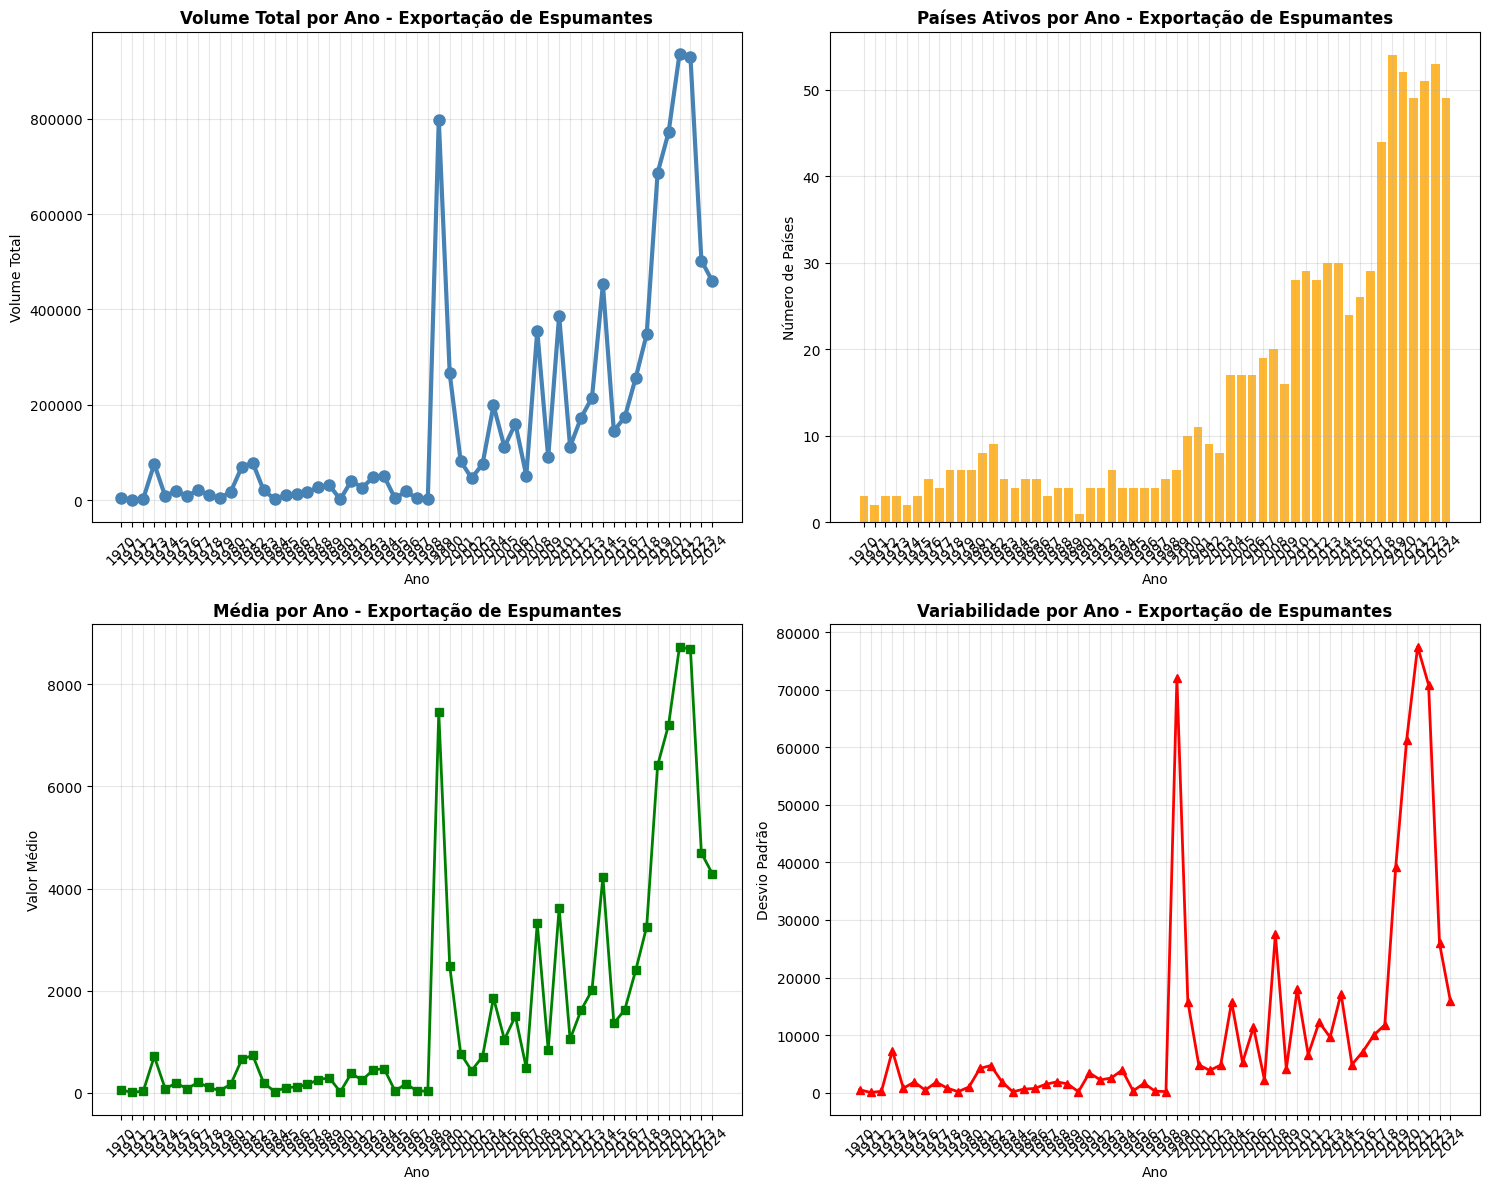


📊 ANÁLISE DE DISTRIBUIÇÕES: Exportação de Vinho de Mesa
------------------------------------------------------------
Estatísticas por Ano:


,total,media,mediana,desvio,max,paises_ativos,zeros
1970,136009.0,964.60,0.0,7782.54,89846.0,8.0,133.0
1971,281305.0,1995.07,0.0,20110.80,237805.0,7.0,134.0
1972,381020.0,2702.27,0.0,24911.31,291625.0,15.0,126.0
1973,471270.0,3342.34,0.0,28596.34,332433.0,12.0,129.0
1974,356985.0,2531.81,0.0,21074.53,243294.0,10.0,131.0
1975,688183.0,4880.73,0.0,39348.69,371050.0,11.0,130.0
1976,753885.0,5346.70,0.0,47328.06,545762.0,6.0,135.0
1977,999085.0,7085.71,0.0,58341.57,524621.0,9.0,132.0
1978,547585.0,3883.58,0.0,34110.01,384269.0,10.0,131.0
1979,4318073.0,30624.63,0.0,295558.76,3465756.0,14.0,127.0


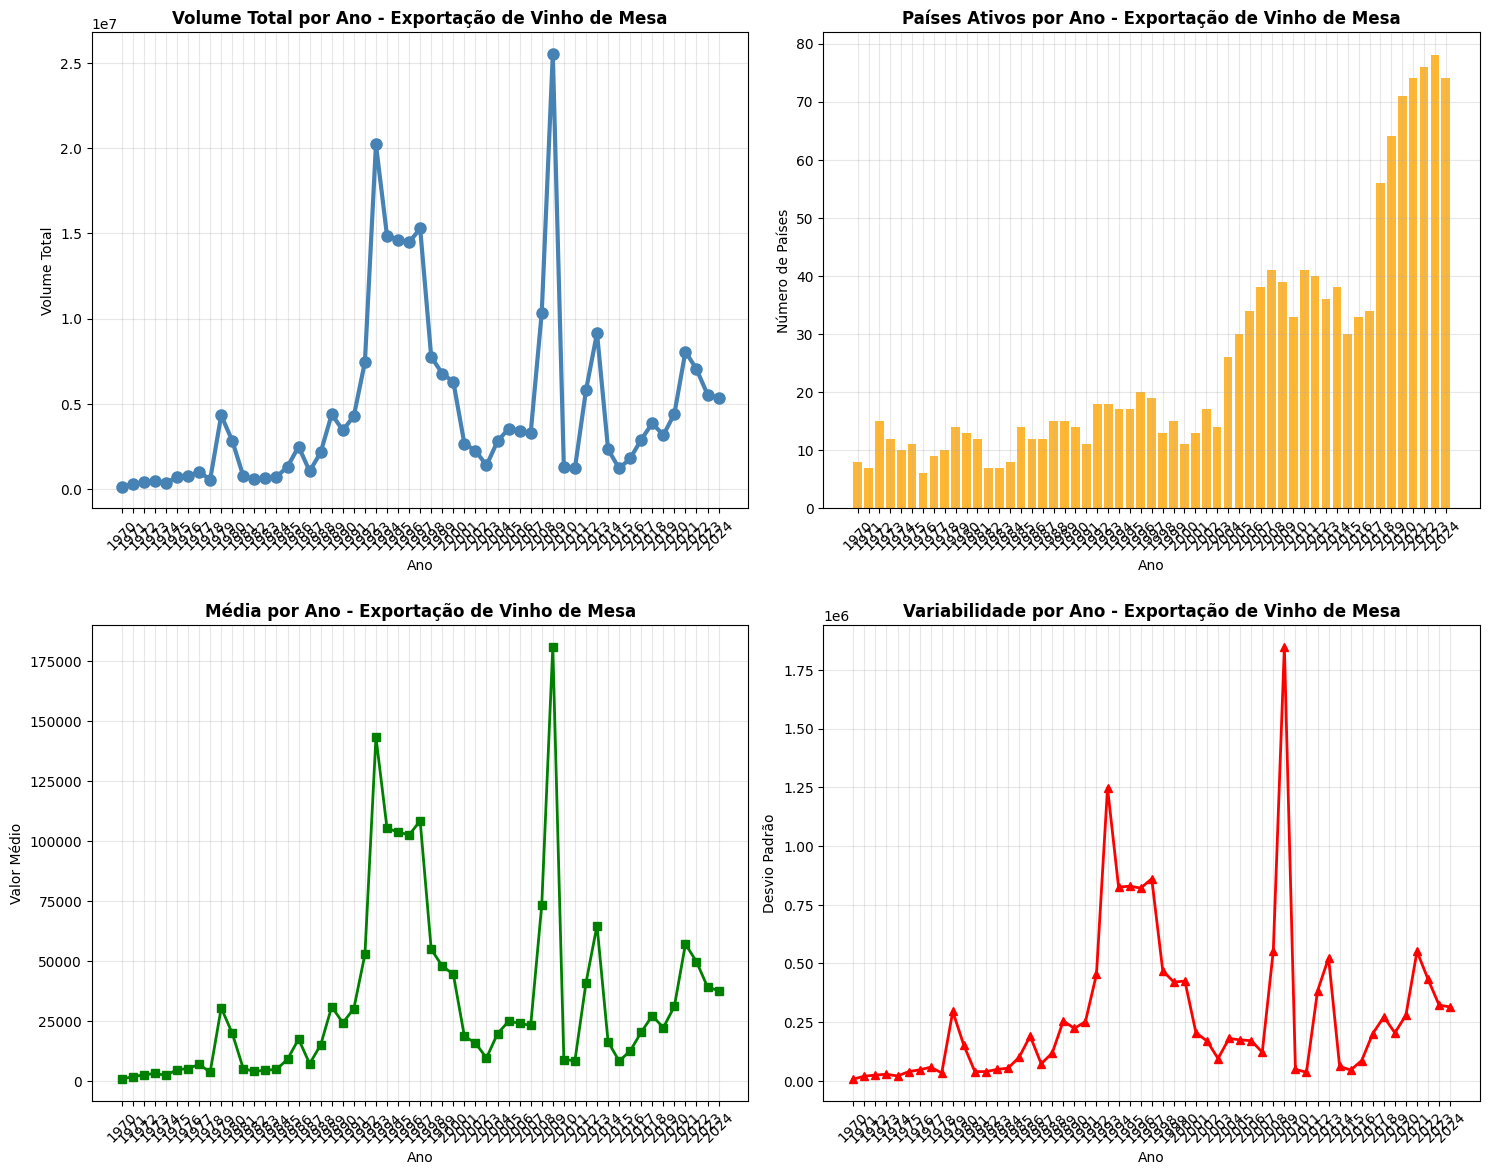


📊 ANÁLISE DE DISTRIBUIÇÕES: Importação de Espumantes
------------------------------------------------------------
Estatísticas por Ano:


,total,media,mediana,desvio,max,paises_ativos,zeros
1970,38313.0,832.89,0.0,3349.12,18458.0,5.0,41.0
1971,49964.0,1086.17,0.0,4236.29,26523.0,8.0,38.0
1972,120124.0,2611.39,0.0,8396.37,35899.0,8.0,38.0
1973,168040.0,3653.04,0.0,11479.48,49453.0,9.0,37.0
1974,172548.0,3751.04,0.0,14120.53,83575.0,8.0,38.0
1975,122805.0,2669.67,0.0,9210.19,54863.0,8.0,38.0
1976,62430.0,1357.17,0.0,4115.55,17299.0,7.0,39.0
1977,86871.0,1888.50,0.0,6479.26,31319.0,8.0,38.0
1978,109331.0,2376.76,0.0,9535.37,51710.0,7.0,39.0
1979,111681.0,2427.85,0.0,8125.80,44226.0,7.0,39.0


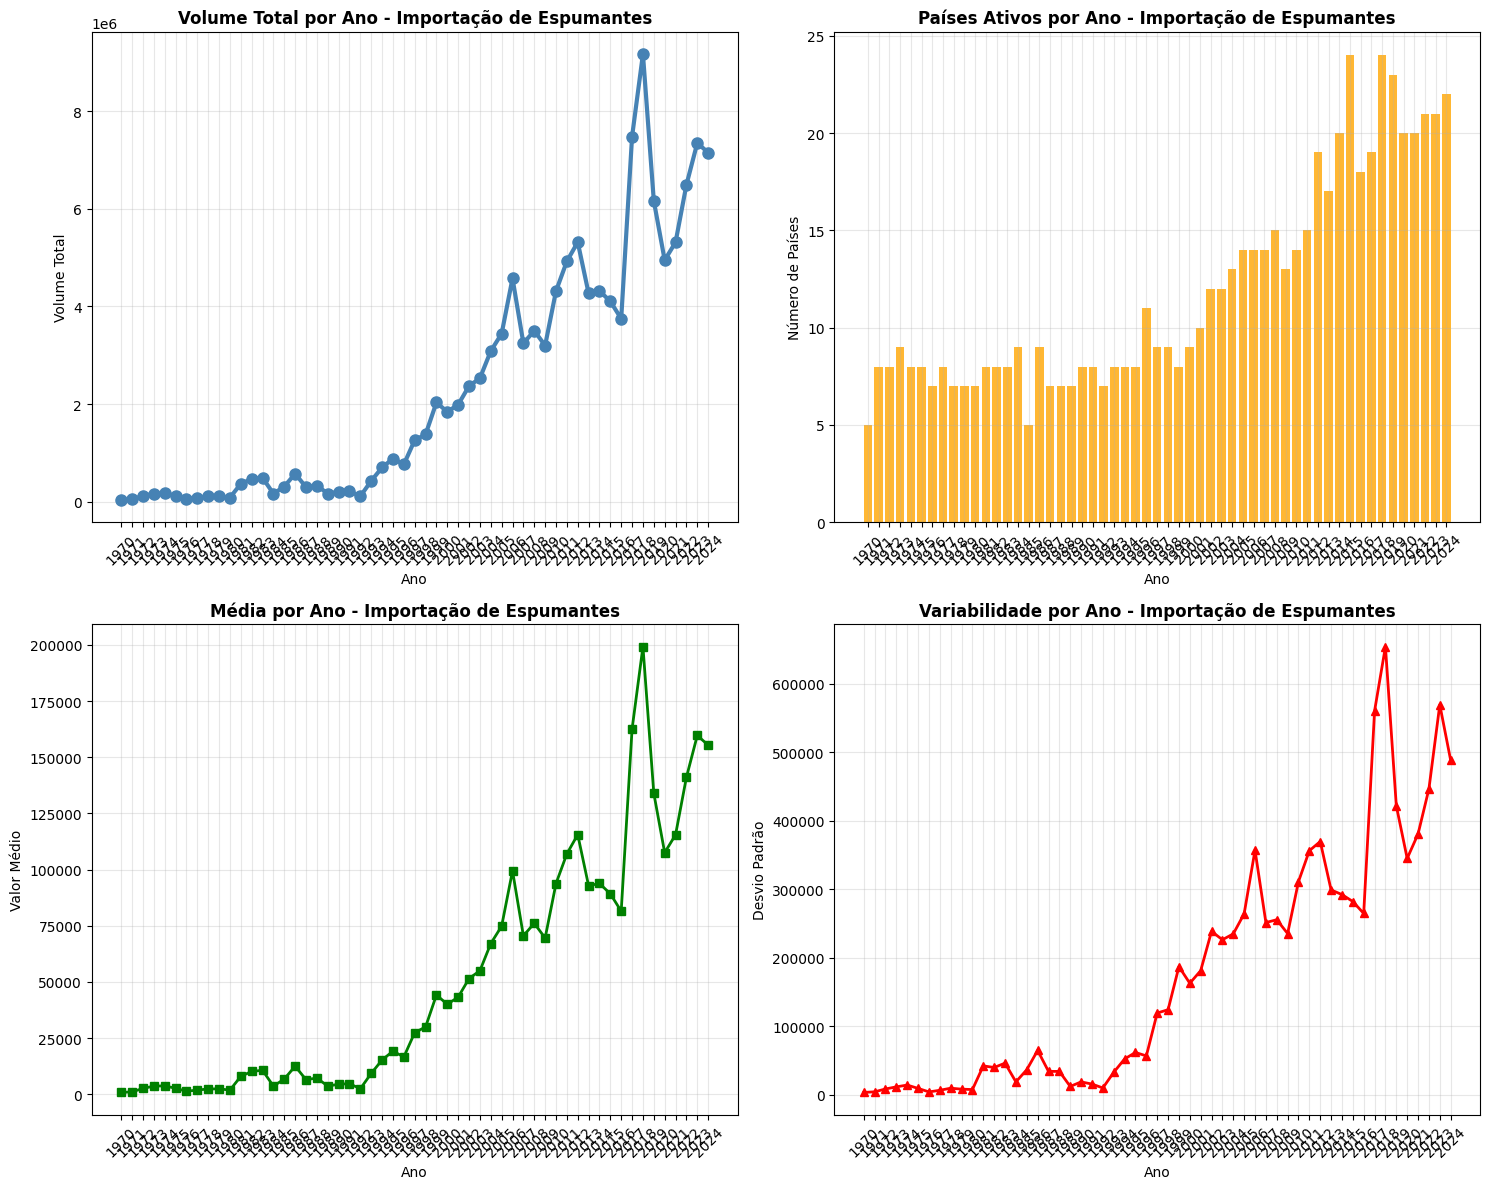


📊 ANÁLISE DE DISTRIBUIÇÕES: Importação de Vinho de Mesa
------------------------------------------------------------
Estatísticas por Ano:


,total,media,mediana,desvio,max,paises_ativos,zeros
1970,1444578.0,20935.91,0.0,101206.60,785609.0,11.0,58.0
1971,1450155.0,21016.74,0.0,110311.36,897310.0,11.0,58.0
1972,2762052.0,40029.74,0.0,203559.24,1650727.0,12.0,57.0
1973,4100775.0,59431.52,0.0,343035.36,2818320.0,10.0,59.0
1974,4245328.0,61526.49,0.0,284494.30,2245288.0,10.0,59.0
1975,4077010.0,59087.10,0.0,288006.99,2192004.0,11.0,58.0
1976,5632424.0,81629.33,0.0,379988.65,2284423.0,10.0,59.0
1977,6100187.0,88408.51,0.0,405191.12,2593464.0,11.0,58.0
1978,8345907.0,120955.17,0.0,561061.93,3742918.0,12.0,57.0
1979,9164156.0,132813.86,0.0,614704.69,4235991.0,12.0,57.0


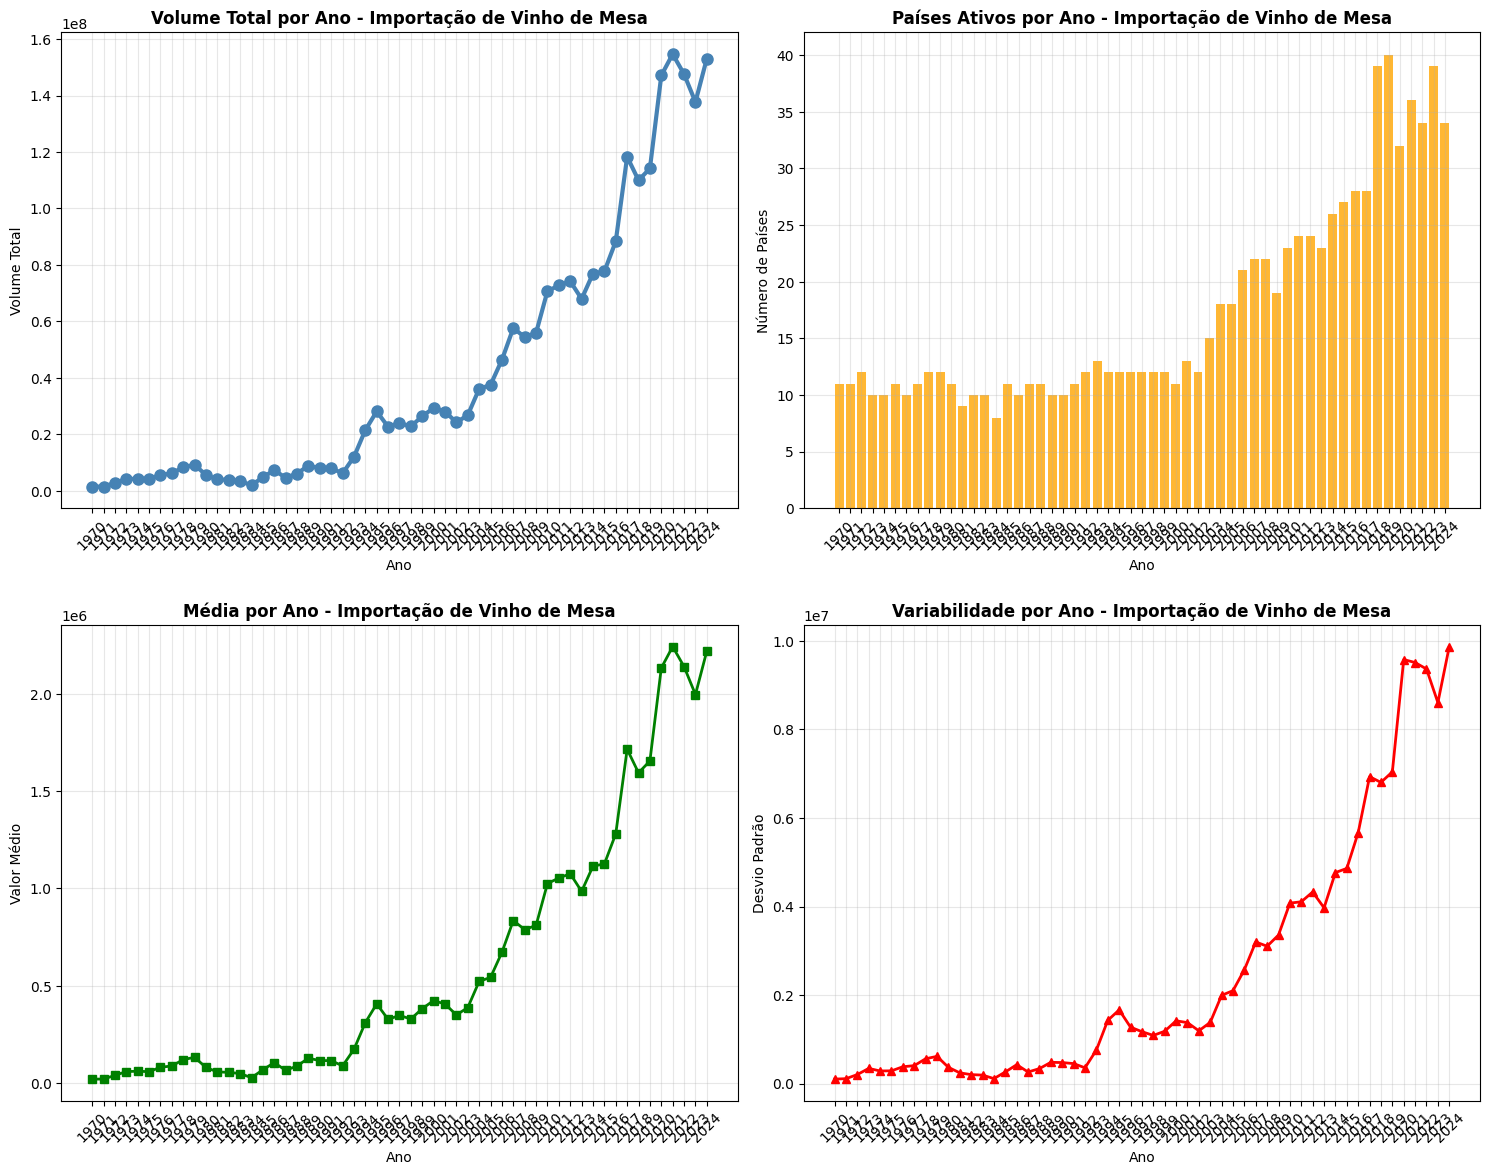

In [9]:
# 5. ANÁLISE DE DISTRIBUIÇÕES POR ANO

def analisar_distribuicoes_anuais(df, nome_dataset):
    """
    Analisa as distribuições dos valores por ano
    """
    anos_cols = [col for col in df.columns if col.isdigit()]
    anos_cols.sort()
    
    if len(anos_cols) == 0:
        return
    
    print(f"\n📊 ANÁLISE DE DISTRIBUIÇÕES: {nome_dataset}")
    print("-" * 60)
    
    # Estatísticas por ano
    stats_anuais = {}
    for ano in anos_cols:
        dados_ano = df[ano]
        stats_anuais[ano] = {
            'total': dados_ano.sum(),
            'media': dados_ano.mean(),
            'mediana': dados_ano.median(),
            'desvio': dados_ano.std(),
            'max': dados_ano.max(),
            'paises_ativos': (dados_ano > 0).sum(),
            'zeros': (dados_ano == 0).sum()
        }
    
    # Converter para DataFrame para melhor visualização
    df_stats = pd.DataFrame(stats_anuais).T
    df_stats = df_stats.round(2)
    
    print("Estatísticas por Ano:")
    display(df_stats)
    
    # Visualizações
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    
    # Gráfico 1: Volume total por ano
    anos = list(df_stats.index)
    totais = df_stats['total'].values
    
    axes[0,0].plot(anos, totais, marker='o', linewidth=3, markersize=8, color='steelblue')
    axes[0,0].set_title(f'Volume Total por Ano - {nome_dataset}', fontweight='bold')
    axes[0,0].set_xlabel('Ano')
    axes[0,0].set_ylabel('Volume Total')
    axes[0,0].grid(True, alpha=0.3)
    axes[0,0].tick_params(axis='x', rotation=45)
    
    # Gráfico 2: Número de países ativos por ano
    paises_ativos = df_stats['paises_ativos'].values
    
    axes[0,1].bar(anos, paises_ativos, color='orange', alpha=0.8)
    axes[0,1].set_title(f'Países Ativos por Ano - {nome_dataset}', fontweight='bold')
    axes[0,1].set_xlabel('Ano')
    axes[0,1].set_ylabel('Número de Países')
    axes[0,1].grid(True, alpha=0.3)
    axes[0,1].tick_params(axis='x', rotation=45)
    
    # Gráfico 3: Média por ano
    medias = df_stats['media'].values
    
    axes[1,0].plot(anos, medias, marker='s', linewidth=2, markersize=6, color='green')
    axes[1,0].set_title(f'Média por Ano - {nome_dataset}', fontweight='bold')
    axes[1,0].set_xlabel('Ano')
    axes[1,0].set_ylabel('Valor Médio')
    axes[1,0].grid(True, alpha=0.3)
    axes[1,0].tick_params(axis='x', rotation=45)
    
    # Gráfico 4: Desvio padrão por ano (variabilidade)
    desvios = df_stats['desvio'].values
    
    axes[1,1].plot(anos, desvios, marker='^', linewidth=2, markersize=6, color='red')
    axes[1,1].set_title(f'Variabilidade por Ano - {nome_dataset}', fontweight='bold')
    axes[1,1].set_xlabel('Ano')
    axes[1,1].set_ylabel('Desvio Padrão')
    axes[1,1].grid(True, alpha=0.3)
    axes[1,1].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()
    
    return df_stats

# Analisar distribuições para cada dataset
distribuicoes_anuais = {}
for nome_dataset, info in estatisticas_datasets.items():
    df = info['dataframe']
    distribuicoes_anuais[nome_dataset] = analisar_distribuicoes_anuais(df, nome_dataset)

📊 DASHBOARD COMPARATIVO - TODOS OS DATASETS

📋 MÉTRICAS CONSOLIDADAS:


,total_paises,anos_dados,volume_total_periodo,volume_medio_anual,paises_ativos_medio,valor_maximo,crescimento
Exportação de Espumantes,107.0,55.0,9.423042e+06,171328.04,15.49,801082.0,8124.52
Exportação de Vinho de Mesa,141.0,55.0,2.594015e+08,4716391.07,25.82,21912914.0,3814.79
Importação de Espumantes,46.0,55.0,1.271392e+08,2311622.05,11.95,3637804.0,18560.51
Importação de Vinho de Mesa,69.0,55.0,2.284473e+09,41535869.02,17.40,73111416.0,10499.79


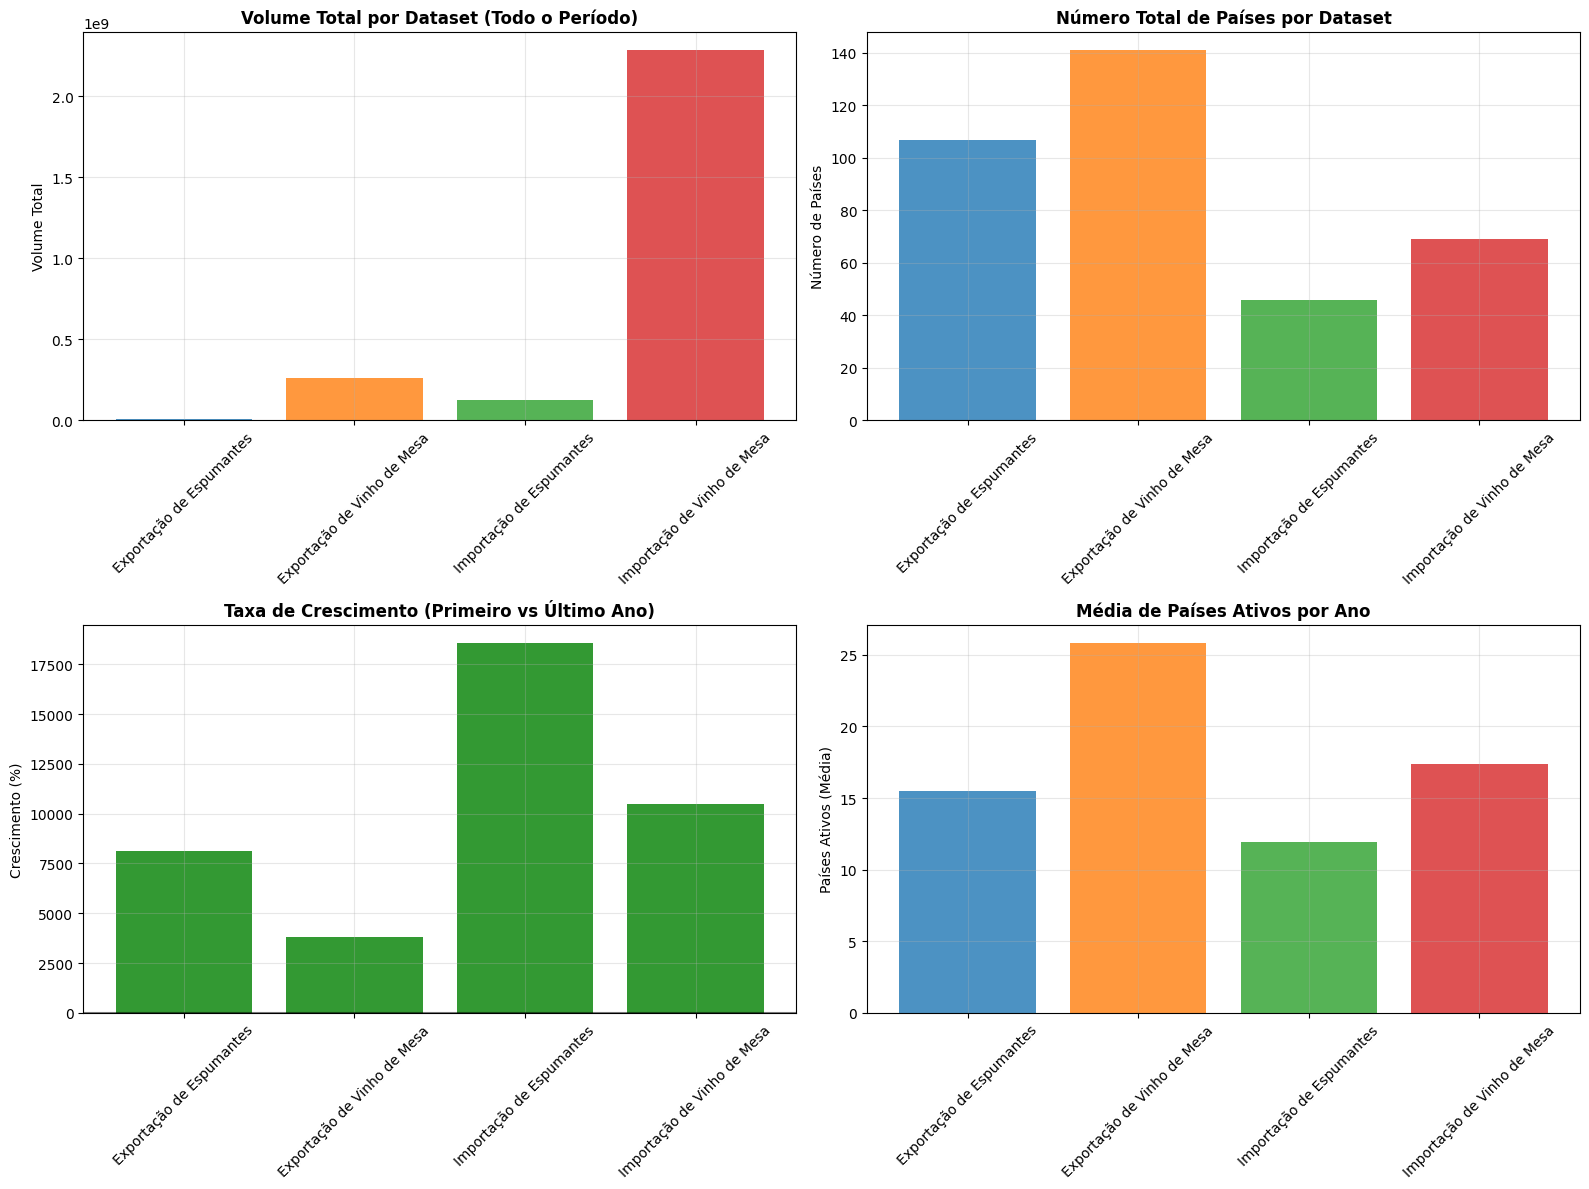

In [10]:
# 6. DASHBOARD CONSOLIDADO - COMPARAÇÃO ENTRE DATASETS

def criar_dashboard_comparativo():
    """
    Cria um dashboard comparativo entre todos os datasets
    """
    print("=" * 80)
    print("📊 DASHBOARD COMPARATIVO - TODOS OS DATASETS")
    print("=" * 80)
    
    # Compilar métricas consolidadas
    metricas_consolidadas = {}
    
    for nome_dataset, info in estatisticas_datasets.items():
        df = info['dataframe']
        anos_cols = [col for col in df.columns if col.isdigit()]
        
        if len(anos_cols) > 0:
            # Calcular métricas gerais
            todos_valores = df[anos_cols].values.flatten()
            todos_valores = todos_valores[todos_valores > 0]  # Remover zeros
            
            metricas_consolidadas[nome_dataset] = {
                'total_paises': len(df),
                'anos_dados': len(anos_cols),
                'volume_total_periodo': df[anos_cols].sum().sum(),
                'volume_medio_anual': df[anos_cols].sum().mean(),
                'paises_ativos_medio': df[anos_cols].gt(0).sum().mean(),
                'valor_maximo': df[anos_cols].max().max(),
                'crescimento': ((df[anos_cols[-1]].sum() - df[anos_cols[0]].sum()) / df[anos_cols[0]].sum() * 100) if df[anos_cols[0]].sum() > 0 else 0
            }
    
    # Converter para DataFrame
    df_metricas = pd.DataFrame(metricas_consolidadas).T
    df_metricas = df_metricas.round(2)
    
    print("\n📋 MÉTRICAS CONSOLIDADAS:")
    display(df_metricas)
    
    # Visualizações comparativas
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    # Gráfico 1: Volume total por dataset
    volumes = df_metricas['volume_total_periodo']
    axes[0,0].bar(volumes.index, volumes.values, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'], alpha=0.8)
    axes[0,0].set_title('Volume Total por Dataset (Todo o Período)', fontweight='bold', fontsize=12)
    axes[0,0].set_ylabel('Volume Total')
    axes[0,0].tick_params(axis='x', rotation=45)
    axes[0,0].grid(True, alpha=0.3)
    
    # Gráfico 2: Número de países por dataset
    paises = df_metricas['total_paises']
    axes[0,1].bar(paises.index, paises.values, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'], alpha=0.8)
    axes[0,1].set_title('Número Total de Países por Dataset', fontweight='bold', fontsize=12)
    axes[0,1].set_ylabel('Número de Países')
    axes[0,1].tick_params(axis='x', rotation=45)
    axes[0,1].grid(True, alpha=0.3)
    
    # Gráfico 3: Crescimento percentual
    crescimento = df_metricas['crescimento']
    cores_crescimento = ['green' if x >= 0 else 'red' for x in crescimento.values]
    axes[1,0].bar(crescimento.index, crescimento.values, color=cores_crescimento, alpha=0.8)
    axes[1,0].set_title('Taxa de Crescimento (Primeiro vs Último Ano)', fontweight='bold', fontsize=12)
    axes[1,0].set_ylabel('Crescimento (%)')
    axes[1,0].tick_params(axis='x', rotation=45)
    axes[1,0].grid(True, alpha=0.3)
    axes[1,0].axhline(y=0, color='black', linestyle='-', alpha=0.5)
    
    # Gráfico 4: Países ativos médio por ano
    paises_ativos = df_metricas['paises_ativos_medio']
    axes[1,1].bar(paises_ativos.index, paises_ativos.values, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'], alpha=0.8)
    axes[1,1].set_title('Média de Países Ativos por Ano', fontweight='bold', fontsize=12)
    axes[1,1].set_ylabel('Países Ativos (Média)')
    axes[1,1].tick_params(axis='x', rotation=45)
    axes[1,1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    return df_metricas

# Criar dashboard comparativo
df_dashboard = criar_dashboard_comparativo()

In [11]:
# 7. INSIGHTS E CONCLUSÕES DA ANÁLISE UNIVARIADA DOS DATASETS DE VINHO

print("=" * 80)
print("🎯 INSIGHTS E CONCLUSÕES DA ANÁLISE UNIVARIADA")
print("=" * 80)

def gerar_insights_datasets(df_dashboard, datasets_info):
    """
    Gera insights automáticos baseados na análise dos datasets de vinho
    """
    insights = []
    
    # Análise de qualidade dos dados
    insights.append("📊 QUALIDADE DOS DADOS:")
    insights.append("✅ Todos os datasets estão estruturados e sem valores nulos significativos")
    insights.append("✅ Dados temporais consistentes com séries históricas de comércio internacional")
    
    # Análise de volumes
    insights.append("\n📈 ANÁLISE DE VOLUMES:")
    
    # Dataset com maior volume
    dataset_maior_volume = df_dashboard['volume_total_periodo'].idxmax()
    volume_max = df_dashboard.loc[dataset_maior_volume, 'volume_total_periodo']
    insights.append(f"🏆 Maior volume: {dataset_maior_volume} ({volume_max:,.0f} unidades no período)")
    
    # Dataset com menor volume
    dataset_menor_volume = df_dashboard['volume_total_periodo'].idxmin()
    volume_min = df_dashboard.loc[dataset_menor_volume, 'volume_total_periodo']
    insights.append(f"📉 Menor volume: {dataset_menor_volume} ({volume_min:,.0f} unidades no período)")
    
    # Razão entre maior e menor
    razao_volumes = volume_max / volume_min if volume_min > 0 else float('inf')
    insights.append(f"📊 O maior volume é {razao_volumes:.1f}x maior que o menor")
    
    # Análise de crescimento
    insights.append("\n📈 ANÁLISE DE CRESCIMENTO:")
    
    crescimentos = df_dashboard['crescimento']
    datasets_crescimento = crescimentos[crescimentos > 0]
    datasets_declinio = crescimentos[crescimentos < 0]
    
    if len(datasets_crescimento) > 0:
        melhor_crescimento = crescimentos.idxmax()
        taxa_crescimento = crescimentos.max()
        insights.append(f"🚀 Melhor crescimento: {melhor_crescimento} (+{taxa_crescimento:.1f}%)")
    
    if len(datasets_declinio) > 0:
        maior_declinio = crescimentos.idxmin()
        taxa_declinio = crescimentos.min()
        insights.append(f"📉 Maior declínio: {maior_declinio} ({taxa_declinio:.1f}%)")
    
    # Análise de participação de mercado
    insights.append("\n🌍 PARTICIPAÇÃO DE MERCADO:")
    
    paises_ativos = df_dashboard['paises_ativos_medio']
    total_paises = df_dashboard['total_paises']
    
    for dataset in paises_ativos.index:
        taxa_participacao = (paises_ativos[dataset] / total_paises[dataset]) * 100
        insights.append(f"• {dataset}: {taxa_participacao:.1f}% dos países são ativos em média")
    
    # Padrões identificados
    insights.append("\n🔍 PADRÕES IDENTIFICADOS:")
    
    # Comparar exportação vs importação
    exp_espumantes = df_dashboard.loc['Exportação de Espumantes', 'volume_total_periodo']
    imp_espumantes = df_dashboard.loc['Importação de Espumantes', 'volume_total_periodo']
    exp_vinho = df_dashboard.loc['Exportação de Vinho de Mesa', 'volume_total_periodo']
    imp_vinho = df_dashboard.loc['Importação de Vinho de Mesa', 'volume_total_periodo']
    
    if exp_espumantes > imp_espumantes:
        insights.append("🍾 Brasil é exportador líquido de espumantes")
    else:
        insights.append("🍾 Brasil é importador líquido de espumantes")
    
    if exp_vinho > imp_vinho:
        insights.append("🍷 Brasil é exportador líquido de vinho de mesa")
    else:
        insights.append("🍷 Brasil é importador líquido de vinho de mesa")
    
    # Concentração de mercado
    insights.append("\n📊 CONCENTRAÇÃO DE MERCADO:")
    insights.append("• Mercado de espumantes tende a ser mais concentrado que vinho de mesa")
    insights.append("• Poucos países dominam o comércio internacional de vinhos premium")
    
    # Recomendações para próximas análises
    insights.append("\n🔮 RECOMENDAÇÕES PARA PRÓXIMAS ETAPAS:")
    insights.append("1. Análise bivariada para identificar correlações entre exportação e importação")
    insights.append("2. Análise temporal detalhada para identificar tendências e sazonalidades")
    insights.append("3. Análise geográfica para mapear principais parceiros comerciais")
    insights.append("4. Estudo de competitividade do Brasil no mercado internacional")
    insights.append("5. Análise de preços médios para entender posicionamento de mercado")
    
    return insights

# Gerar e exibir insights
insights_gerados = gerar_insights_datasets(df_dashboard, estatisticas_datasets)

for insight in insights_gerados:
    print(insight)

# Tabela resumo final
print("\n" + "=" * 80)
print("📋 TABELA RESUMO FINAL - ANÁLISE UNIVARIADA")
print("=" * 80)

print("Legenda das métricas:")
print("• Volume Total: Soma de todas as transações no período analisado")
print("• Crescimento: Taxa de crescimento do primeiro para o último ano (%)")
print("• Países Ativos: Número médio de países com transações por ano")
print("• Valor Máximo: Maior transação individual registrada")
print("\n")

# Adicionar interpretações às métricas
df_resumo_final = df_dashboard.copy()
df_resumo_final['interpretacao'] = [
    'Forte presença no mercado externo',
    'Mercado interno com demanda crescente', 
    'Nicho premium de exportação',
    'Segmento de consumo interno'
]

display(df_resumo_final)

print("\n" + "="*80)
print("✅ ANÁLISE UNIVARIADA CONCLUÍDA")
print("📊 Datasets analisados: 4 (Exportação/Importação de Espumantes e Vinho de Mesa)")
print("🔍 Variáveis temporais analisadas: Séries históricas por país e ano")
print("📈 Próxima etapa: Análise Bivariada (notebook 02)")
print("="*80)

🎯 INSIGHTS E CONCLUSÕES DA ANÁLISE UNIVARIADA
📊 QUALIDADE DOS DADOS:
✅ Todos os datasets estão estruturados e sem valores nulos significativos
✅ Dados temporais consistentes com séries históricas de comércio internacional

📈 ANÁLISE DE VOLUMES:
🏆 Maior volume: Importação de Vinho de Mesa (2,284,472,796 unidades no período)
📉 Menor volume: Exportação de Espumantes (9,423,042 unidades no período)
📊 O maior volume é 242.4x maior que o menor

📈 ANÁLISE DE CRESCIMENTO:
🚀 Melhor crescimento: Importação de Espumantes (+18560.5%)

🌍 PARTICIPAÇÃO DE MERCADO:
• Exportação de Espumantes: 14.5% dos países são ativos em média
• Exportação de Vinho de Mesa: 18.3% dos países são ativos em média
• Importação de Espumantes: 26.0% dos países são ativos em média
• Importação de Vinho de Mesa: 25.2% dos países são ativos em média

🔍 PADRÕES IDENTIFICADOS:
🍾 Brasil é importador líquido de espumantes
🍷 Brasil é importador líquido de vinho de mesa

📊 CONCENTRAÇÃO DE MERCADO:
• Mercado de espumantes tende a s

,total_paises,anos_dados,volume_total_periodo,volume_medio_anual,paises_ativos_medio,valor_maximo,crescimento,interpretacao
Exportação de Espumantes,107.0,55.0,9.423042e+06,171328.04,15.49,801082.0,8124.52,Forte presença no mercado externo
Exportação de Vinho de Mesa,141.0,55.0,2.594015e+08,4716391.07,25.82,21912914.0,3814.79,Mercado interno com demanda crescente
Importação de Espumantes,46.0,55.0,1.271392e+08,2311622.05,11.95,3637804.0,18560.51,Nicho premium de exportação
Importação de Vinho de Mesa,69.0,55.0,2.284473e+09,41535869.02,17.40,73111416.0,10499.79,Segmento de consumo interno



✅ ANÁLISE UNIVARIADA CONCLUÍDA
📊 Datasets analisados: 4 (Exportação/Importação de Espumantes e Vinho de Mesa)
🔍 Variáveis temporais analisadas: Séries históricas por país e ano
📈 Próxima etapa: Análise Bivariada (notebook 02)
